# 07 — Kondisi data sebelum Machine Learning (Bab 4.3, 5.1)

Notebook ini **hanya membaca** data bersih di `/datalake/processed/` dan menjawab pertanyaan yang menentukan preprocessing (notebook 08) dan feature engineering (notebook 09):

1. Seperti apa ketiga dataset (baris, kolom, kelas)?
2. Kolom mana yang ada di dataset mana?
3. Seberapa tidak seimbang kelasnya?
4. Berapa detik rekaman yang harus diambil supaya kejadiannya ikut?
5. Komponen mana (E, N, Z) yang bisa dipakai, dan kenapa perlu normalisasi?
6. Kolom CSV mana yang boleh menjadi fitur (waktu, sensor, lokasi)?
7. Berapa stasiun merekam satu kejadian?
8. Apakah frekuensi sinyal berbeda antar kelas?

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyspark.sql import functions as F, Window

pd.set_option('display.width', 200, 'display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
spark = spark_session('a2_audit')
meta = spark.read.parquet(f'{HDFS}{PROCESSED}/metadata')
wf = spark.read.parquet(f'{HDFS}{PROCESSED}/waveforms')

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/09 10:36:32 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/09 10:36:32 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


## 1. Ringkasan tiga dataset

In [2]:
raw = {d: spark.read.csv(f'{HDFS}{RAW}/{d}/{d}_metadata.csv', header=True) for d in DATASETS}
size = lambda path: int(sh(f'hdfs dfs -du -s {path}', quiet=True).split()[0])

s = (meta.groupBy('dataset')
     .agg(F.count('*').alias('rows_clean'), F.concat_ws(', ', F.array_sort(F.collect_set('label'))).alias('classes'),
          F.countDistinct('event_id').alias('events'), F.countDistinct('station_network_code', 'station_code').alias('stations'),
          F.min(F.year('trace_start_time')).alias('year_from'), F.max(F.year('trace_start_time')).alias('year_to'),
          F.first('n_samples').alias('samples_per_comp'))
     .toPandas().set_index('dataset').loc[DATASETS])
s.insert(0, 'rows_raw', [raw[d].count() for d in DATASETS])
s.insert(1, 'columns_raw', [len(raw[d].columns) for d in DATASETS])
s['duration_s'] = (s.samples_per_comp - 1) / 100
s['hdf5_gb'] = [round(size(f'{RAW}/{d}/{d}_waveforms.hdf5') / 1e9, 1) for d in DATASETS]
s['parquet_gb'] = [round(size(f'{PROCESSED}/waveforms/dataset={d}') / 1e9, 1) for d in DATASETS]
save_md(s.reset_index(), 'a2_dataset_summary', 'Ringkasan tiga dataset (data bersih)')
s

,rows_raw,columns_raw,rows_clean,classes,events,stations,year_from,year_to,samples_per_comp,duration_s,hdf5_gb,parquet_gb
dataset,,,,,,,,,,,,
comcat,178939,37,178839,"earthquake, explosion",46023,639,2002,2022,15001,150.0,67.3,53.7
exotic,9267,17,8912,surface_event,5425,128,2002,2021,18001,180.0,4.1,2.5
noise,51017,11,50227,noise,0,599,2002,2022,15001,150.0,18.5,15.1


Tiga dataset punya **isi dan bentuk berbeda**: ComCat berisi 2 kelas, Exotic dan Noise masing-masing 1 kelas. Exotic lebih panjang (180 s vs 150 s), dan Noise tidak punya `event_id` (tidak ada kejadian).

## 2. Kolom per dataset dan persentase kosong
Abu-abu = kolom **tidak ada** di file CSV dataset tersebut. Angka = % baris yang kosong.

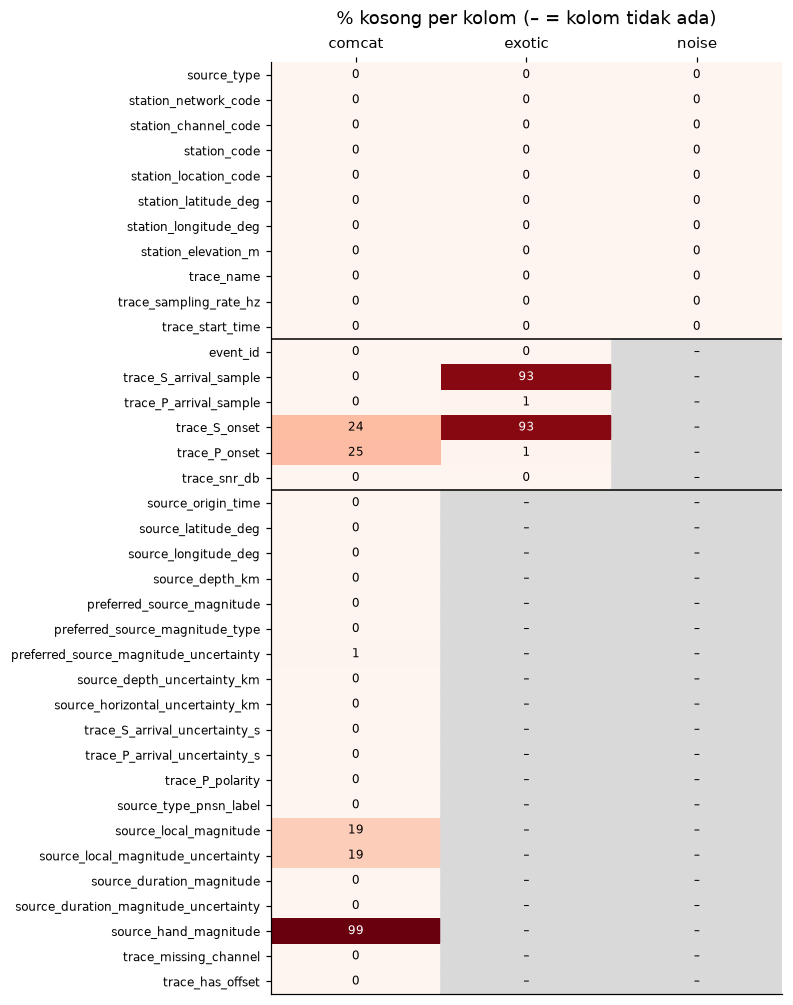

In [3]:
cols = raw['comcat'].columns
presence = {c: sum(c in raw[d].columns for d in DATASETS) for c in cols}
cols = sorted(cols, key=lambda c: -presence[c])
null_pct = {}
for d in DATASETS:
    sub = meta.filter(F.col('dataset') == d)
    n = sub.count()
    nulls = sub.select([F.sum(F.col(f'`{c}`').isNull().cast('int')).alias(c) for c in cols]).first().asDict()
    null_pct[d] = [100 * nulls[c] / n if c in raw[d].columns else np.nan for c in cols]
nulls = pd.DataFrame(null_pct, index=cols)

fig, ax = plt.subplots(figsize=(6, 11))
ax.imshow(nulls.fillna(-1).clip(lower=0).values, cmap='Reds', vmin=0, vmax=100, aspect='auto')
for i, c in enumerate(cols):
    for j, d in enumerate(DATASETS):
        v = nulls.loc[c, d]
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color='#d9d9d9'))
            ax.text(j, i, '–', ha='center', va='center', fontsize=8)
        else:
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 60 else 'black')
ax.set_xticks(range(3), DATASETS); ax.xaxis.tick_top()
ax.set_yticks(range(len(cols)), cols, fontsize=8)
for y in (10.5, 16.5):
    ax.axhline(y, color='black', lw=1)
ax.set_title('% kosong per kolom (– = kolom tidak ada)', pad=25)
save_fig('a2_columns_null'); plt.show()

- **11 kolom** ada di ketiga dataset (stasiun, info rekaman, label). Hanya kolom ini yang adil untuk keempat kelas → dasar pemilihan kolom di notebook 08.
- **6 kolom** (event_id, waktu tiba P/S, SNR) hanya ada di ComCat & Exotic → keberadaannya saja sudah membedakan "bukan noise".
- **20 kolom** hanya ada di ComCat (magnitudo, lokasi sumber, dll.) → keberadaannya saja sudah membedakan "gempa/ledakan".

## 3. Keseimbangan kelas

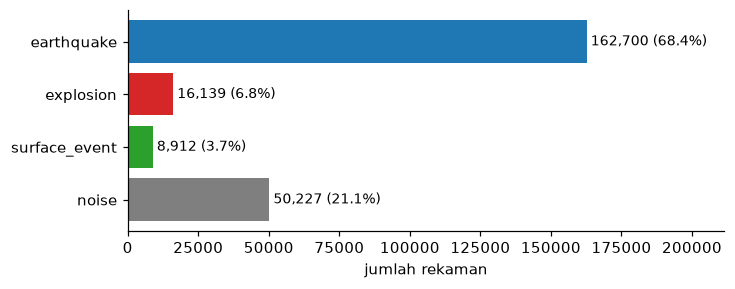

,dataset,count,pct
label,,,
earthquake,comcat,162700,68.4
explosion,comcat,16139,6.8
surface_event,exotic,8912,3.7
noise,noise,50227,21.1


In [4]:
cls = meta.groupBy('label', 'dataset').count().toPandas().set_index('label').loc[CLASSES]
cls['pct'] = (100 * cls['count'] / cls['count'].sum()).round(1)
save_md(cls.reset_index(), 'a2_class_balance', 'Jumlah rekaman per kelas (data bersih)')
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(cls.index[::-1], cls['count'][::-1], color=[COLORS[c] for c in cls.index[::-1]])
for i, (n, p) in enumerate(zip(cls['count'][::-1], cls['pct'][::-1])):
    ax.text(n, i, f' {n:,} ({p}%)', va='center', fontsize=9)
ax.set_xlim(0, cls['count'].max() * 1.3); ax.set_xlabel('jumlah rekaman')
save_fig('a2_class_balance'); plt.show()
cls

Gempa 18× lebih banyak dari surface event. Model yang selalu menebak "earthquake" sudah benar 68% → **akurasi saja menyesatkan**. Perlu bobot kelas (notebook 08) dan metrik per kelas / macro-F1 saat evaluasi.

## 4. Berapa detik rekaman yang diambil?
Semua rekaman harus punya panjang yang sama. Pertanyaannya: kalau dipotong dari detik 0, berapa panjang yang cukup supaya **kejadiannya ikut terpotong**? Garis putus = pilihan panjang 60, 100, dan 150 detik. Noise tidak punya P.

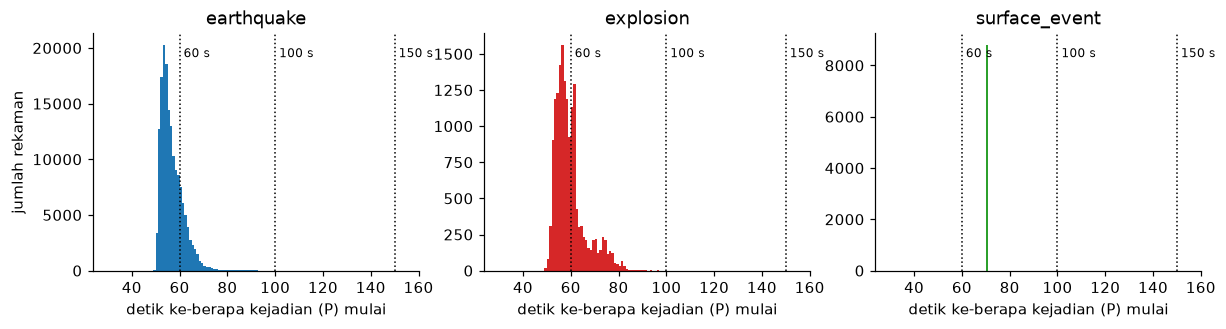

,rows,length_s,p_missing,p_min_s,p_median_s,p_max_s,pct_event_inside_0_60s,pct_event_inside_0_100s,pct_event_inside_0_150s
label,,,,,,,,,
earthquake,162700,150,0,36.29,55.57,106.15,78.5,100.0,100.0
explosion,16139,150,0,49.27,58.02,96.08,62.8,100.0,100.0
surface_event,8912,180,108,70.00,70.00,70.00,0.0,100.0,100.0
noise,50227,150,50227,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
pos = meta.select('label', 'n_samples', 'trace_P_arrival_sample').toPandas()
pos['p_s'] = pos.trace_P_arrival_sample / 100
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, c in zip(axes, ['earthquake', 'explosion', 'surface_event']):
    ax.hist(pos.loc[pos.label == c, 'p_s'].dropna(), bins=np.arange(30, 155, 1), color=COLORS[c])
    for x in (60, 100, 150):
        ax.axvline(x, color='k', ls=':', lw=1); ax.text(x, ax.get_ylim()[1] * .9, f' {x} s', fontsize=8)
    ax.set_title(c); ax.set_xlabel('detik ke-berapa kejadian (P) mulai')
axes[0].set_ylabel('jumlah rekaman')
save_fig('a2_p_position'); plt.show()

ptab = (pos.groupby('label').agg(rows=('label', 'size'), length_s=('n_samples', lambda x: round((x.iloc[0] - 1) / 100)),
                                 p_missing=('p_s', lambda x: x.isna().sum()), p_min_s=('p_s', 'min'),
                                 p_median_s=('p_s', 'median'), p_max_s=('p_s', 'max'))
        .loc[CLASSES])
for end in (60, 100, 150):
    ptab[f'pct_event_inside_0_{end}s'] = pos.dropna(subset=['p_s']).groupby('label').p_s.apply(lambda x: round(100 * (x < end).mean(), 1))
save_md(ptab.reset_index(), 'a2_p_position', 'Kapan kejadian mulai, dan berapa % masuk potongan 0–60/100/150 s')
ptab

- **0–60 s tidak bisa:** surface event selalu mulai di detik ke-70, jadi **0%** surface event masuk; 21.5% gempa dan 37.2% ledakan juga terpotong.
- **0–100 s:** hampir semua awal kejadian masuk (24 gempa mulai setelah detik 100), tapi surface event hanya kebagian 30 detik sinyal.
- **0–150 s:** **100%** awal kejadian masuk, dan ini panjang penuh rekaman ComCat/Noise. Exotic (180 s) hanya kehilangan 30 detik terakhirnya. → **dipilih 0–150 s**, tanpa perlu kolom P.
- Catatan: posisi awal kejadian berbeda per kelas (surface event selalu di detik 70, gempa ±56). Supaya model tidak menghafal posisi, saat training potongan digeser acak (notebook 09).

## 5. Komponen E, N, Z dan amplitudo
Setiap waveform punya 3 komponen: **E** (timur–barat), **N** (utara–selatan), **Z** (vertikal). Spark membaca ketiganya dari seluruh 237,978 waveform (66.5 GB); hanya angka puncak per komponen yang dibawa ke driver. Komponen "kosong" = semua angkanya nol.

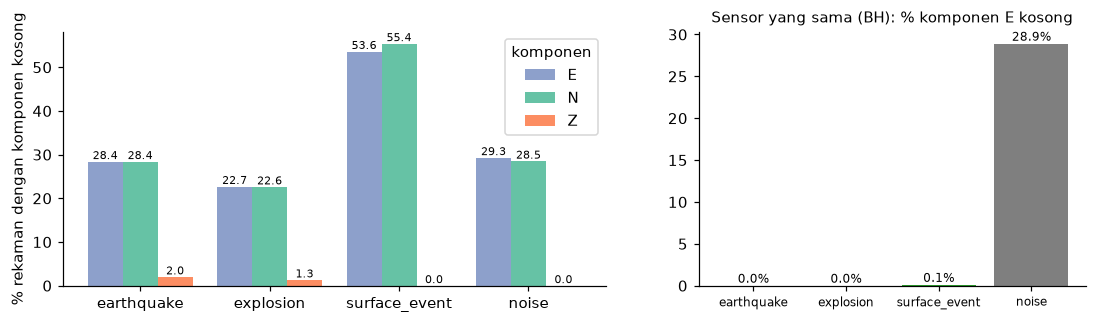

,rows,E_empty,N_empty,Z_empty
label,,,,
earthquake,162700,28.4,28.4,2.0
explosion,16139,22.7,22.6,1.3
surface_event,8912,53.6,55.4,0.0
noise,50227,29.3,28.5,0.0


rows  E_empty  N_empty  Z_empty
label         station_channel_code                                  
earthquake    BH                    49256      0.0      0.0      0.0
              EH                    90352     51.1     51.1      3.5
              HH                    23092      0.5      0.3      0.7
explosion     BH                     4741      0.0      0.0      0.0
              EH                     7987     45.6     45.6      2.0
              HH                     3411      0.4      0.2      1.3
noise         BH                    15840     28.9     27.2      0.0
              EH                    26945     32.7     32.6      0.0
              HH                     7442     18.0     16.4      0.0
surface_event BH                     1605      0.1      0.1      0.0
              EH                     7034     67.9     70.1      0.0
              HH                      273      1.1      1.1      0.0

In [6]:
peak = lambda c: F.expr(f'aggregate({c}, 0D, (a, x) -> greatest(a, abs(x)))').alias(f'peak_{c}')
amp = (wf.select('dataset', 'trace_name', peak('e'), peak('n'), peak('z'))
       .join(F.broadcast(meta.select('dataset', 'trace_name', 'label', 'station_channel_code')), ['dataset', 'trace_name'])
       .toPandas())
for c in 'enz':
    amp[f'{c.upper()}_empty'] = amp[f'peak_{c}'] == 0
pct = lambda g: (100 * g[['E_empty', 'N_empty', 'Z_empty']].mean()).round(1)
by_class = amp.groupby('label').apply(pct).loc[CLASSES]
by_class.insert(0, 'rows', amp.groupby('label').size())
empty = amp.groupby(['label', 'station_channel_code']).apply(pct)
empty.insert(0, 'rows', amp.groupby(['label', 'station_channel_code']).size())
save_md(by_class.reset_index(), 'a2_empty_components_by_class', '% komponen kosong per kelas')
save_md(empty.reset_index(), 'a2_empty_components', '% komponen kosong per kelas × sensor')

fig, axes = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw={'width_ratios': [1.4, 1]})
x = np.arange(len(CLASSES))
for k, (comp, col) in enumerate(zip(['E_empty', 'N_empty', 'Z_empty'], ['#8da0cb', '#66c2a5', '#fc8d62'])):
    b = axes[0].bar(x + (k - 1) * .27, by_class[comp], .27, color=col, label=comp[0])
    axes[0].bar_label(b, fmt='%.1f', fontsize=7)
axes[0].set_xticks(x, CLASSES); axes[0].set_ylabel('% rekaman dengan komponen kosong'); axes[0].legend(title='komponen')
bh = empty.xs('BH', level='station_channel_code')['E_empty'].loc[CLASSES]
b = axes[1].bar(CLASSES, bh, color=[COLORS[c] for c in CLASSES]); axes[1].bar_label(b, fmt='%.1f%%', fontsize=8)
axes[1].set_title('Sensor yang sama (BH): % komponen E kosong', fontsize=10); axes[1].tick_params(axis='x', labelsize=8)
save_fig('a2_empty_components'); plt.show()
display(by_class)
empty

- **E dan N kosong pada 23–55% rekaman** (gempa 28%, ledakan 23%, noise 29%, surface event 54%), terutama sensor EH yang banyak hanya mengukur arah vertikal.
- Pada **sensor yang sama (BH)**, E kosong di **28.9% noise** tetapi **0.0% gempa**. Kalau E/N dipakai, model bisa belajar "E kosong → noise", bukan bentuk sinyal.
- **Z kosong hanya 2% gempa dan 1.3% ledakan** (3,511 rekaman, tidak pernah pada noise/surface event) → rekaman ini dibuang, sisanya lengkap.
- Keputusan: **hanya komponen Z**. Yang hilang: gerakan horizontal (gelombang S paling kuat di E/N).

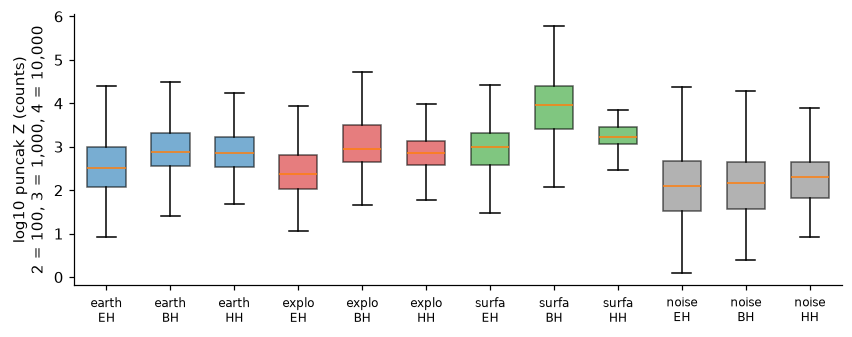

,station,station_channel_code,peak_z_counts
0,UW.GSM,EH,208.0
1,UW.HTW,EH,1214.0
2,UW.TTW,BH,1344.0
3,UW.RMW,EH,2324.0


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.2))
data, ticks, colors = [], [], []
for c in CLASSES:
    for sname in ['EH', 'BH', 'HH']:
        v = amp.loc[(amp.label == c) & (amp.station_channel_code == sname) & ~amp.Z_empty, 'peak_z']
        data.append(np.log10(v)); ticks.append(f'{c[:5]}\n{sname}'); colors.append(COLORS[c])
bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=.6)
for b, col in zip(bp['boxes'], colors):
    b.set_facecolor(col); b.set_alpha(.6)
ax.set_xticks(range(1, len(ticks) + 1), ticks, fontsize=8)
ax.set_ylabel('log10 puncak Z (counts)\n2 = 100, 3 = 1,000, 4 = 10,000')
save_fig('a2_amplitude_by_sensor'); plt.show()

ev_pick = (meta.filter("label = 'earthquake'").groupBy('event_id')
           .agg(F.collect_set('station_channel_code').alias('s'), F.count('*').alias('n'))
           .filter(F.array_contains('s', 'EH') & F.array_contains('s', 'BH') & F.col('n').between(4, 6))
           .orderBy('event_id').first().event_id)
one = (wf.join(F.broadcast(meta.filter(F.col('event_id') == ev_pick)
                           .select('dataset', 'trace_name', 'station_network_code', 'station_code', 'station_channel_code')), ['dataset', 'trace_name'])
       .select(F.concat_ws('.', 'station_network_code', 'station_code').alias('station'), 'station_channel_code',
               F.round(F.expr('aggregate(z, 0D, (a, x) -> greatest(a, abs(x)))')).alias('peak_z_counts'))
       .toPandas().sort_values('peak_z_counts').reset_index(drop=True))
save_md(one, 'a2_one_event_amplitude', f'Satu gempa ({ev_pick}) di beberapa stasiun: puncak Z (counts)')
one

- Sumbu y = besar getaran terbesar dalam **counts** (angka mentah sensor). Dalam satu kelas, angkanya bergeser karena **jenis sensor** (contoh: surface event BH ±10,000 vs EH ±1,000).
- Tabel di atas: **satu gempa yang sama** di beberapa stasiun, puncaknya berbeda sampai belasan kali lipat, karena jarak dan jenis sensor, bukan jenis kejadian.
- → setiap rekaman **dinormalisasi** (z-score, notebook 08), jadi yang dipelajari model adalah **bentuk** sinyal, bukan besar angka.

## 6. Kolom CSV yang boleh menjadi fitur: waktu, sensor, lokasi?
Waktu = waktu mulai rekaman (`trace_start_time`), diubah ke waktu lokal Pacific (America/Los_Angeles), karena aktivitas manusia mengikuti jam lokal.

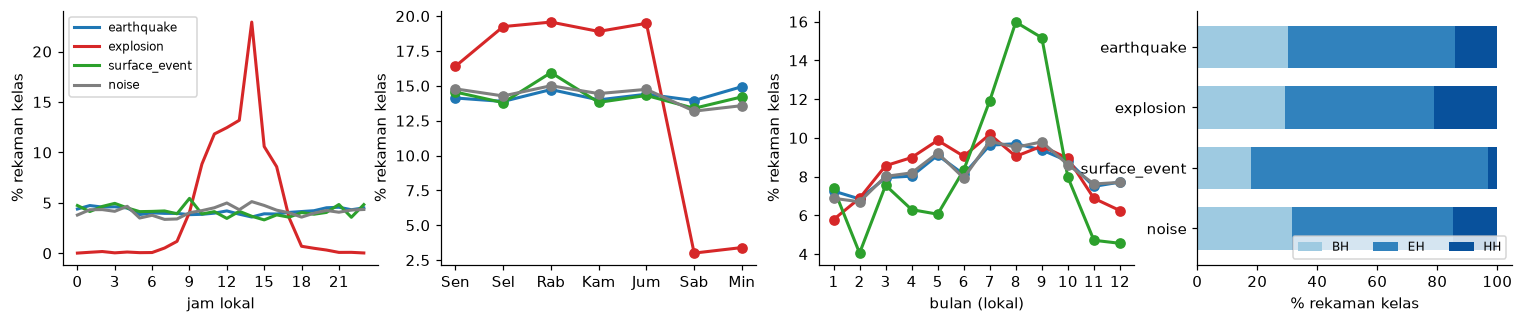

,pct_weekday_08_17,pct_weekday,pct_jul_sep
label,,,
earthquake,24.9,71.1,28.7
explosion,87.8,93.6,28.8
surface_event,25.5,72.4,43.1
noise,29.8,73.2,29.1


In [8]:
local = meta.withColumn('t_local', F.from_utc_timestamp('trace_start_time', 'America/Los_Angeles'))
hours = local.groupBy('label', F.hour('t_local').alias('hour')).count().toPandas()
dow = local.groupBy('label', ((F.dayofweek('t_local') + 5) % 7).alias('dow')).count().toPandas()
month = local.groupBy('label', F.month('t_local').alias('month')).count().toPandas()
sens = meta.groupBy('label', 'station_channel_code').count().toPandas()

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
axes = axes.ravel()
for c in CLASSES:
    h = hours[hours.label == c].set_index('hour')['count'].reindex(range(24), fill_value=0)
    axes[0].plot(h.index, 100 * h / h.sum(), color=COLORS[c], label=c, lw=2)
    d = dow[dow.label == c].set_index('dow')['count'].reindex(range(7), fill_value=0)
    axes[1].plot(d.index, 100 * d / d.sum(), color=COLORS[c], marker='o', lw=2)
    mo = month[month.label == c].set_index('month')['count'].reindex(range(1, 13), fill_value=0)
    axes[2].plot(mo.index, 100 * mo / mo.sum(), color=COLORS[c], marker='o', lw=2)
axes[0].set(xlabel='jam lokal', ylabel='% rekaman kelas', xticks=range(0, 24, 3)); axes[0].legend(fontsize=8)
axes[1].set(xticks=range(7), xticklabels=['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min'], ylabel='% rekaman kelas')
axes[2].set(xticks=range(1, 13), xlabel='bulan (lokal)', ylabel='% rekaman kelas')
st = sens.pivot(index='label', columns='station_channel_code', values='count').loc[CLASSES]
st = 100 * st.div(st.sum(axis=1), axis=0)
st.plot.barh(stacked=True, ax=axes[3], color=['#9ecae1', '#3182bd', '#08519c'], width=.7)
axes[3].set(xlabel='% rekaman kelas', ylabel=''); axes[3].invert_yaxis(); axes[3].legend(fontsize=8, ncols=3, loc='upper center', bbox_to_anchor=(.5, -.2), frameon=False)
fig.tight_layout(); save_fig('a2_time_sensor_by_class'); plt.show()

hrs = local.withColumn('h', F.hour('t_local')).withColumn('wd', F.dayofweek('t_local').between(2, 6))
ctx = (hrs.groupBy('label').agg(F.round(100 * F.avg((F.col('h').between(8, 16) & F.col('wd')).cast('int')), 1).alias('pct_weekday_08_17'),
                               F.round(100 * F.avg(F.col('wd').cast('int')), 1).alias('pct_weekday'),
                               F.round(100 * F.avg(F.month('t_local').between(7, 9).cast('int')), 1).alias('pct_jul_sep'))
       .toPandas().set_index('label').loc[CLASSES])
save_md(ctx.reset_index(), 'a2_context_by_class', 'Waktu lokal per kelas')
ctx

- **Jam:** 87.8% ledakan terjadi pada hari kerja pukul 08–17 (ledakan tambang/konstruksi), kelas lain ±25–30%.
- **Hari dalam minggu:** ledakan turun tajam di Sabtu–Minggu, kelas lain rata setiap hari → siklus aktivitas manusia.
- **Bulan / musim:** 43% surface event terjadi Juli–September (longsoran batu & aliran debris musim panas), kelas lain ±29% → siklus musim.
- **Jenis sensor:** EH, BH, dan HH ada di **semua** kelas.
- Waktu dan sensor **diketahui saat sinyal masuk**, jadi sah dipakai sebagai fitur konteks.

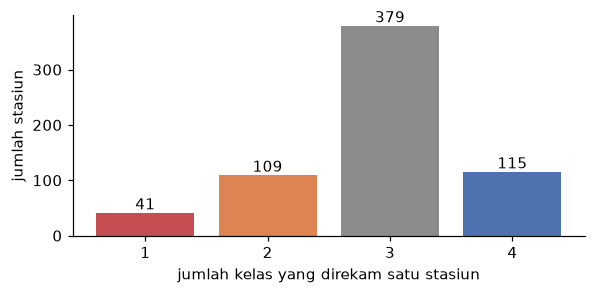

,stations
n_classes_recorded,
1,41
2,109
3,379
4,115


In [9]:
st_cls = (meta.groupBy(F.concat_ws('.', 'station_network_code', 'station_code').alias('station'))
          .agg(F.countDistinct('label').alias('n_classes')).toPandas())
st_tab = st_cls.n_classes.value_counts().sort_index().rename('stations').to_frame()
st_tab.index.name = 'n_classes_recorded'
save_md(st_tab.reset_index(), 'a2_stations_by_n_classes', 'Berapa kelas yang direkam setiap stasiun')
fig, ax = plt.subplots(figsize=(6, 2.6))
b = ax.bar(st_tab.index.astype(str), st_tab.stations, color=['#c44e52', '#dd8452', '#8c8c8c', '#4c72b0'])
ax.bar_label(b); ax.set(xlabel='jumlah kelas yang direkam satu stasiun', ylabel='jumlah stasiun')
save_fig('a2_stations_by_n_classes'); plt.show()
st_tab

- **Lokasi stasiun tidak dipakai.** Dari 644 stasiun hanya **115** yang merekam keempat kelas, dan **41 stasiun hanya merekam satu kelas**. Di stasiun seperti itu, lokasi sudah menjadi jawabannya: model bisa menebak kelas dari *tempat* tanpa melihat sinyal.

## 7. Berapa stasiun merekam satu kejadian?

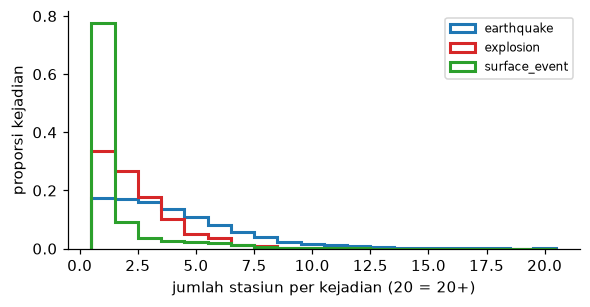

,mean,median,max
label,,,
earthquake,4.11,3.0,41
explosion,2.52,2.0,19
surface_event,1.64,1.0,16


In [10]:
per_ev = meta.filter('event_id IS NOT NULL').groupBy('label', 'event_id').count().toPandas()
fig, ax = plt.subplots(figsize=(6, 2.8))
for c in ['earthquake', 'explosion', 'surface_event']:
    v = per_ev.loc[per_ev.label == c, 'count'].clip(upper=20)
    ax.hist(v, bins=np.arange(.5, 21.5), histtype='step', lw=2, color=COLORS[c], density=True, label=c)
ax.set(xlabel='jumlah stasiun per kejadian (20 = 20+)', ylabel='proporsi kejadian'); ax.legend(fontsize=8)
save_fig('a2_stations_per_event'); plt.show()
spe = per_ev.groupby('label')['count'].agg(['mean', 'median', 'max']).round(2).loc[['earthquake', 'explosion', 'surface_event']]
save_md(spe.reset_index(), 'a2_stations_per_event', 'Jumlah stasiun yang merekam satu kejadian')
spe

Satu gempa rata-rata direkam 4.1 stasiun (ledakan 2.5, surface event 1.6). Setiap rekaman stasiun menjadi **satu baris dan satu prediksi**. Data dibagi train/val/test **acak per rekaman** (notebook 08); konsekuensinya, rekaman lain dari kejadian yang sama bisa ada di data uji → dicatat sebagai keterbatasan.

## 8. Sebaran per tahun

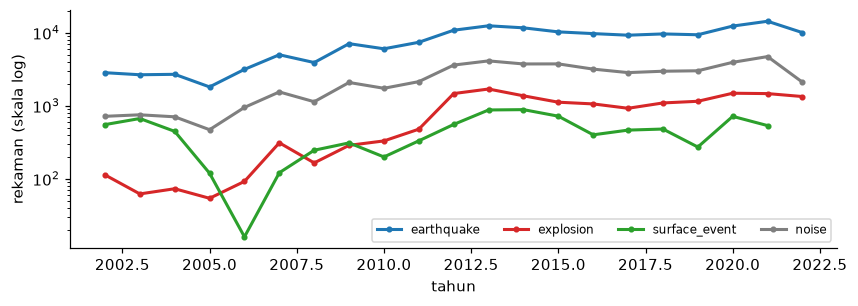

In [11]:
yr = meta.groupBy('label', F.year('trace_start_time').alias('year')).count().toPandas()
fig, ax = plt.subplots(figsize=(9, 2.8))
for c in CLASSES:
    y = yr[yr.label == c].sort_values('year')
    ax.plot(y.year, y['count'], color=COLORS[c], marker='o', ms=3, lw=2, label=c)
ax.set(yscale='log', xlabel='tahun', ylabel='rekaman (skala log)'); ax.legend(fontsize=8, ncols=4)
save_fig('a2_records_per_year'); plt.show()

Keempat kelas ada di hampir semua tahun 2002–2022, jadi pembagian acak tetap mewakili seluruh periode.

## 9. Frekuensi sinyal per kelas dan contoh waveform
Sampel acak 300 rekaman per kelas (seed 42). Spektrum dihitung dari 20 detik setelah awal kejadian (noise: dari detik ke-75), tanpa filter.

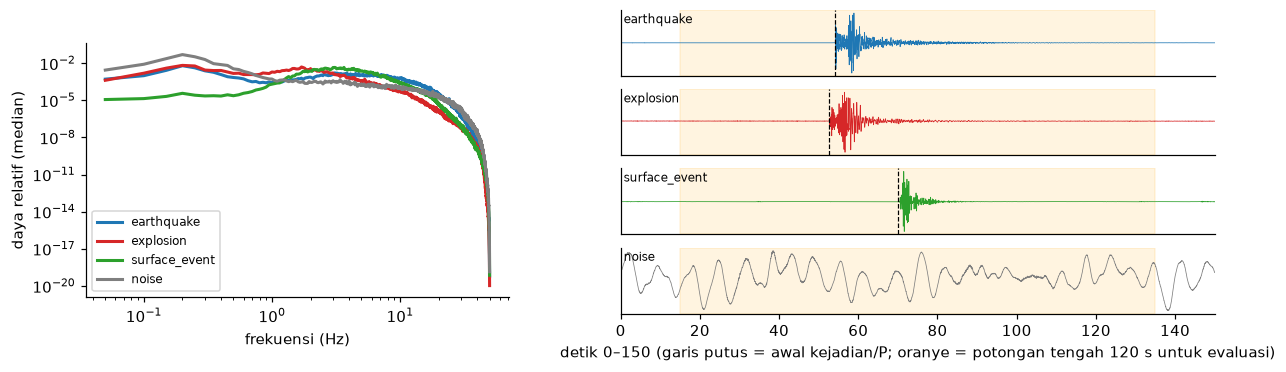

In [12]:
pick = (meta.filter("label = 'noise' OR trace_P_arrival_sample IS NOT NULL")
        .withColumn('k', F.row_number().over(Window.partitionBy('label').orderBy(F.rand(42)))).filter('k <= 300')
        .select('dataset', 'trace_name', 'label', 'trace_P_arrival_sample', 'snr_z'))
smp = wf.select('dataset', 'trace_name', 'z').join(F.broadcast(pick), ['dataset', 'trace_name']).toPandas()
smp['p'] = smp.trace_P_arrival_sample.fillna(7500).astype(int)

f = np.fft.rfftfreq(2000, 1 / 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw={'width_ratios': [1, 1.2]})
for c in CLASSES:
    psd = []
    for z, p in smp.loc[smp.label == c, ['z', 'p']].itertuples(index=False):
        x = np.asarray(z[p:p + 2000]); x = x - x.mean()
        pw = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2
        psd.append(pw / (pw.sum() + 1e-20))
    axes[0].loglog(f[1:], np.median(psd, axis=0)[1:], color=COLORS[c], lw=2, label=c)
axes[0].set(xlabel='frekuensi (Hz)', ylabel='daya relatif (median)'); axes[0].legend(fontsize=8)

ex = smp[smp.label != 'noise'].sort_values('snr_z', ascending=False).groupby('label').head(1)
ex = pd.concat([ex, smp[smp.label == 'noise'].head(1)]).set_index('label').loc[CLASSES]
axes[1].axis('off')
for i, (c, r) in enumerate(ex.iterrows()):
    a = fig.add_axes([0.53, 0.78 - i * 0.24, 0.45, 0.2])
    z = np.asarray(r.z)[:15000]; t = np.arange(len(z)) / 100
    a.plot(t, z / np.abs(z).max(), color=COLORS[c], lw=.5)
    a.axvspan(15, 135, color='orange', alpha=.12)
    if c != 'noise':
        a.axvline(r.p / 100, color='k', lw=.8, ls='--')
    a.set_yticks([]); a.text(0.005, 0.8, c, transform=a.transAxes, fontsize=8)
    a.set_xlim(0, 150)
    if i < 3: a.set_xticks([])
a.set_xlabel('detik 0–150 (garis putus = awal kejadian/P; oranye = potongan tengah 120 s untuk evaluasi)')
save_fig('a2_spectrum_and_examples'); plt.show()

- Isi frekuensi berbeda antar kelas: noise didominasi gelombang lambat <1 Hz (gelombang laut), kejadian lokal berenergi di ±1–20 Hz, dan proporsi frekuensi tinggi vs rendah berbeda antara gempa, ledakan, dan surface event.
- Karena informasinya tersebar di banyak frekuensi, sinyal **tidak difilter**. Lapisan pertama CNN berfungsi sebagai kumpulan filter yang **dipelajari sendiri** dari data (notebook 09).

## 10. Ukuran data: kenapa butuh Spark

In [13]:
n = meta.count()
gb = lambda x: round(x / 1e9, 1)
sz = pd.DataFrame({'stage': ['3 komponen, rekaman penuh (float64)', 'hanya Z, rekaman penuh (float64)',
                             'input CNN: Z 0–150 s (float32)'],
                   'gb': [gb(n * 3 * 15001 * 8), gb(n * 15001 * 8), gb(n * 15000 * 4)]})
save_md(sz, 'a2_data_size', 'Ukuran data pada tiap tahap (perkiraan dari jumlah angka)')
sz

,stage,gb
0,"3 komponen, rekaman penuh (float64)",85.7
1,"hanya Z, rekaman penuh (float64)",28.6
2,input CNN: Z 0–150 s (float32),14.3


Data mentah (±86 GB) dan input CNN (±14 GB) lebih besar dari RAM (24 GB) → pemotongan & normalisasi dikerjakan **Spark secara paralel dari HDFS**, dan training CNN membaca data per potongan (batch), tidak sekaligus.

## Kesimpulan → keputusan untuk notebook 08–09
| Temuan | Keputusan |
|---|---|
| 11 kolom bersama; kolom lain hanya ada di sebagian dataset | Gabung jadi satu tabel; fitur CSV hanya dari 11 kolom bersama |
| 41 stasiun hanya merekam 1 kelas | Lokasi stasiun tidak dipakai |
| Waktu & sensor diketahui saat sinyal masuk; ledakan siang hari kerja, surface event musim panas | Fitur konteks: jam, hari dalam minggu, hari dalam tahun (sin/cos), jenis sensor |
| E/N kosong 23–55% dan polanya beda per kelas; Z kosong hanya 1.5% | Hanya Z; buang 3,511 rekaman Z kosong |
| 0–60 s memotong semua surface event; 0–150 s memuat 100% awal kejadian | Potong 0–150 s untuk semua rekaman, tanpa kolom P |
| Posisi awal kejadian berbeda per kelas | Geser acak (random crop 120 s) saat training |
| Amplitudo ditentukan sensor & jarak | Normalisasi z-score per rekaman |
| Informasi tersebar di banyak frekuensi | Tanpa filter; CNN belajar filternya sendiri |
| Kelas tidak seimbang (68% vs 3.7%) | Simpan semua data + bobot kelas |

In [14]:
spark.stop()